In [1]:

import numpy as np 
import pandas as pd 


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

In [3]:
import glob

CSV_NAME = "rwanda_o_level_final_dataset_100000.csv"

# 1) Look for the file in attached Kaggle inputs (or the current folder if running elsewhere)
matches = []
for root in ["/kaggle/input", "."]:
    matches += glob.glob(f"{root}/**/{CSV_NAME}", recursive=True)

# 2) Not attached? Download it directly (needs Internet ON in Kaggle notebook settings)
if not matches:
    import kagglehub
    folder = kagglehub.dataset_download("ntambaraetienne/rwanda-o-level-final-dataset-100000")
    matches = glob.glob(f"{folder}/**/{CSV_NAME}", recursive=True)

DATA_PATH = matches[0]
print("Using dataset:", DATA_PATH)
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())

Using dataset: /kaggle/input/datasets/ntambaraetienne/rwanda-o-level-final-dataset-100000/rwanda_o_level_final_dataset_100000.csv
Dataset loaded successfully
Dataset shape: (100000, 13)


,Student_ID,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
0,S3-000001,Female,68.8,84.2,59.3,74.0,80.7,62.2,74.6,NaN,68.4,69.91,Pass
1,S3-000002,Female,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,71.82,Pass
2,S3-000003,Female,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,81.28,Pass
3,S3-000004,Female,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,63.08,Pass
4,S3-000005,Female,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,59.39,Pass


In [4]:
print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())
df.info()
display(df.describe(include="all").T)
print(df.columns.tolist())

Dataset shape: (100000, 13)


,Student_ID,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
0,S3-000001,Female,68.8,84.2,59.3,74.0,80.7,62.2,74.6,NaN,68.4,69.91,Pass
1,S3-000002,Female,66.6,63.8,68.7,72.7,74.1,77.9,75.4,79.8,67.4,71.82,Pass
2,S3-000003,Female,72.8,79.1,78.3,79.0,81.5,84.5,92.0,88.8,75.5,81.28,Pass
3,S3-000004,Female,64.5,62.1,71.0,69.7,42.8,68.7,65.1,60.0,63.8,63.08,Pass
4,S3-000005,Female,48.3,62.5,51.0,63.5,60.8,73.5,59.9,54.8,60.2,59.39,Pass


,Student_ID,Gender,Biology_and_Health_Sciences,Chemistry,English,Entrepreneurship,Geography_and_Environment,History_and_Citizenship,Kinyarwanda,Mathematics,Physics,Total_Marks,Status
99995,S3-099996,Female,80.1,73.3,80.3,68.4,81.0,64.6,79.2,164.9,73.0,74.98,Pass
99996,S3-099997,Male,66.2,67.8,48.1,61.7,70.0,60.5,61.8,45.4,75.5,61.89,Pass
99997,S3-099998,Female,35.6,46.3,58.1,48.2,52.8,42.7,54.3,37.9,39.7,46.18,Fail
99998,S3-099999,Male,56.6,57.2,47.7,60.4,79.8,52.5,66.1,56.1,65.0,60.16,Pass
99999,S3-100000,Female,54.9,51.3,70.1,55.2,55.0,44.9,60.2,33.0,44.4,52.11,Pass


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Student_ID                   100000 non-null  object 
 1   Gender                       98000 non-null   object 
 2   Biology_and_Health_Sciences  97000 non-null   float64
 3   Chemistry                    96500 non-null   float64
 4   English                      97500 non-null   float64
 5   Entrepreneurship             97000 non-null   float64
 6   Geography_and_Environment    97500 non-null   float64
 7   History_and_Citizenship      97000 non-null   float64
 8   Kinyarwanda                  97500 non-null   float64
 9   Mathematics                  96500 non-null   float64
 10  Physics                      97000 non-null   float64
 11  Total_Marks                  100000 non-null  float64
 12  Status                       100000 non-null  object 
dtype

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,100000,100000,S3-099984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,98000,2,Female,49805,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Biology_and_Health_Sciences,97000.0,NaN,NaN,NaN,60.957022,15.089635,5.5,50.7,61.0,71.3,100.0
Chemistry,96500.0,NaN,NaN,NaN,58.948269,15.949491,0.0,48.1,58.9,69.8,100.0
English,97500.0,NaN,NaN,NaN,61.982296,13.48041,4.7,52.8,62.0,71.2,100.0
Entrepreneurship,97000.0,NaN,NaN,NaN,64.993448,12.643258,12.7,56.4,65.0,73.6,100.0
Geography_and_Environment,97500.0,NaN,NaN,NaN,62.961237,13.493945,10.0,53.8,62.9,72.1,100.0
History_and_Citizenship,97000.0,NaN,NaN,NaN,61.97049,13.513293,7.8,52.8,62.0,71.1,100.0
Kinyarwanda,97500.0,NaN,NaN,NaN,66.009851,12.717407,14.8,57.4,66.0,74.6,100.0
Mathematics,96500.0,NaN,NaN,NaN,58.957545,20.041861,0.0,46.6,58.1,69.9,219.9


['Student_ID', 'Gender', 'Biology_and_Health_Sciences', 'Chemistry', 'English', 'Entrepreneurship', 'Geography_and_Environment', 'History_and_Citizenship', 'Kinyarwanda', 'Mathematics', 'Physics', 'Total_Marks', 'Status']


In [5]:
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())

print("Data types:")
display(df.dtypes)

print("Unique values:")
display(df.nunique().sort_values())

Missing values:


Chemistry                      3500
Mathematics                    3500
Biology_and_Health_Sciences    3000
Entrepreneurship               3000
Physics                        3000
History_and_Citizenship        3000
Kinyarwanda                    2500
English                        2500
Geography_and_Environment      2500
Gender                         2000
Student_ID                        0
Total_Marks                       0
Status                            0
dtype: int64

Duplicate rows: 0
Data types:


Student_ID                      object
Gender                          object
Biology_and_Health_Sciences    float64
Chemistry                      float64
English                        float64
Entrepreneurship               float64
Geography_and_Environment      float64
History_and_Citizenship        float64
Kinyarwanda                    float64
Mathematics                    float64
Physics                        float64
Total_Marks                    float64
Status                          object
dtype: object

Unique values:


Gender                              2
Status                              2
Kinyarwanda                       775
Entrepreneurship                  786
Geography_and_Environment         830
History_and_Citizenship           831
English                           842
Biology_and_Health_Sciences       894
Chemistry                         938
Physics                           943
Mathematics                      1492
Total_Marks                      6031
Student_ID                     100000
dtype: int64

In [6]:
df = df.drop_duplicates()
df = df.dropna(subset=["Status"])

print("Dataset shape:", df.shape)
print("\nMissing value percentages:")
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

print("\nStatus distribution:")
print(df["Status"].value_counts())

print("\nStatus percentages:")
print((df["Status"].value_counts(normalize=True) * 100).round(2))

print("\nAverage total marks by status:")
print(df.groupby("Status")["Total_Marks"].agg(["count", "mean", "min", "max"]))

Dataset shape: (100000, 13)

Missing value percentages:
Chemistry                      3.5
Mathematics                    3.5
Biology_and_Health_Sciences    3.0
Entrepreneurship               3.0
Physics                        3.0
History_and_Citizenship        3.0
Kinyarwanda                    2.5
English                        2.5
Geography_and_Environment      2.5
Gender                         2.0
Student_ID                     0.0
Total_Marks                    0.0
Status                         0.0
dtype: float64

Status distribution:
Status
Pass    82742
Fail    17258
Name: count, dtype: int64

Status percentages:
Status
Pass    82.74
Fail    17.26
Name: proportion, dtype: float64

Average total marks by status:
        count       mean    min    max
Status                                
Fail    17258  43.407168  22.16  49.99
Pass    82742  65.445111  50.00  99.63


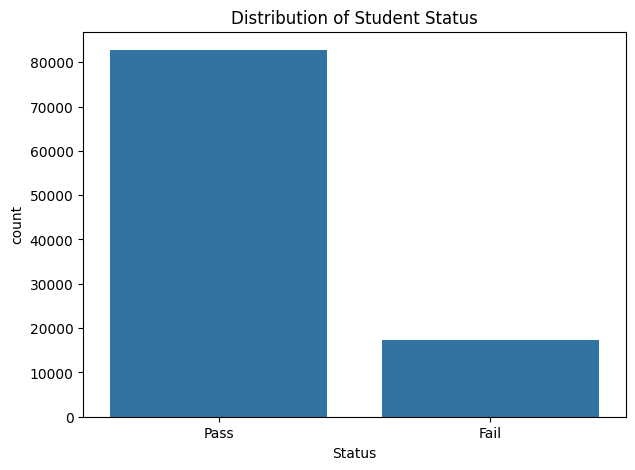

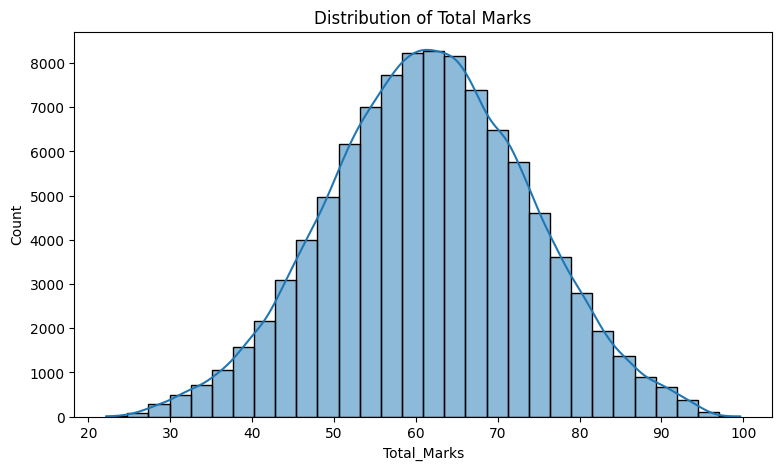

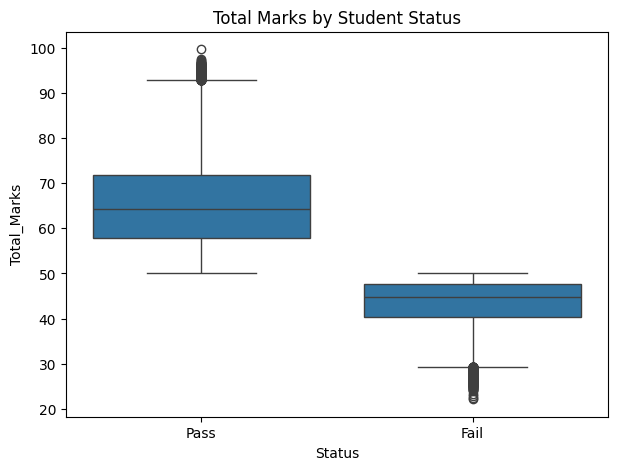

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Status")
plt.title("Distribution of Student Status")
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Total_Marks", bins=30, kde=True)
plt.title("Distribution of Total Marks")
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Status", y="Total_Marks")
plt.title("Total Marks by Student Status")
plt.show()

In [8]:
X = df.drop(columns=["Status", "Total_Marks", "Student_ID"])
y = df["Status"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (100000, 10)
Target shape: (100000,)

Features:
['Gender', 'Biology_and_Health_Sciences', 'Chemistry', 'English', 'Entrepreneurship', 'Geography_and_Environment', 'History_and_Citizenship', 'Kinyarwanda', 'Mathematics', 'Physics']


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (80000, 10)
Testing features: (20000, 10)
Training target: (80000,)
Testing target: (20000,)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (80000, 11)
Processed testing shape: (20000, 11)


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import time

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

results = []
trained_models = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    duration = time.time() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "Training Time (seconds)": round(duration, 2)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
print(results_df.to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  Training Time (seconds)
      Random Forest   0.98410   0.984011 0.98410  0.984033                     6.20
Logistic Regression   0.98395   0.983886 0.98395  0.983910                     0.48
      Decision Tree   0.96245   0.962562 0.96245  0.962504                     0.96


## 5-Fold Stratified Cross-Validation

A single 80/20 split gives one score that depends on which students landed in the test set. Cross-validation repeats the train/validate cycle on 5 different folds of the **training data**, so we get a mean score *and* its spread for each model.

Two details matter here:
- **`StratifiedKFold`** keeps the Pass/Fail ratio (~83/17) the same in every fold.
- Each model is wrapped in a **`Pipeline` with the preprocessor**, so imputation, scaling and encoding are re-fitted inside each fold. Fitting them on all the data first would leak information from the validation fold.

The test set stays untouched until the final evaluation.

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted",
    "f1_macro": "f1_macro",   # gives the minority "Fail" class equal weight
}

cv_summary = []
cv_fold_scores = {}

for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    start = time.time()
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring,
        n_jobs=1,                 # RandomForest already uses n_jobs=-1 internally
        return_train_score=True,
    )
    duration = time.time() - start
    cv_fold_scores[name] = scores

    cv_summary.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "CV Macro F1": scores["test_f1_macro"].mean(),
        "Train F1 (mean)": scores["train_f1"].mean(),
        "CV Time (s)": round(duration, 1),
    })

cv_results_df = pd.DataFrame(cv_summary).sort_values("CV F1", ascending=False).reset_index(drop=True)
print(f"{N_SPLITS}-fold stratified cross-validation (training set only)\n")
print(cv_results_df.round(4).to_string(index=False))

5-fold stratified cross-validation (training set only)

              Model  CV Accuracy  Accuracy Std  CV Precision  CV Recall  CV F1  F1 Std  CV Macro F1  Train F1 (mean)  CV Time (s)
Logistic Regression       0.9840        0.0005        0.9840     0.9840 0.9840  0.0005       0.9719           0.9841         12.8
      Random Forest       0.9826        0.0006        0.9825     0.9826 0.9825  0.0006       0.9693           1.0000         34.6
      Decision Tree       0.9611        0.0008        0.9612     0.9611 0.9611  0.0008       0.9320           1.0000         14.1


,Logistic Regression,Decision Tree,Random Forest
Fold 1,0.9841,0.9617,0.9833
Fold 2,0.9847,0.9621,0.9828
Fold 3,0.9835,0.9615,0.9820
Fold 4,0.9833,0.9602,0.9816
Fold 5,0.9843,0.9602,0.9829


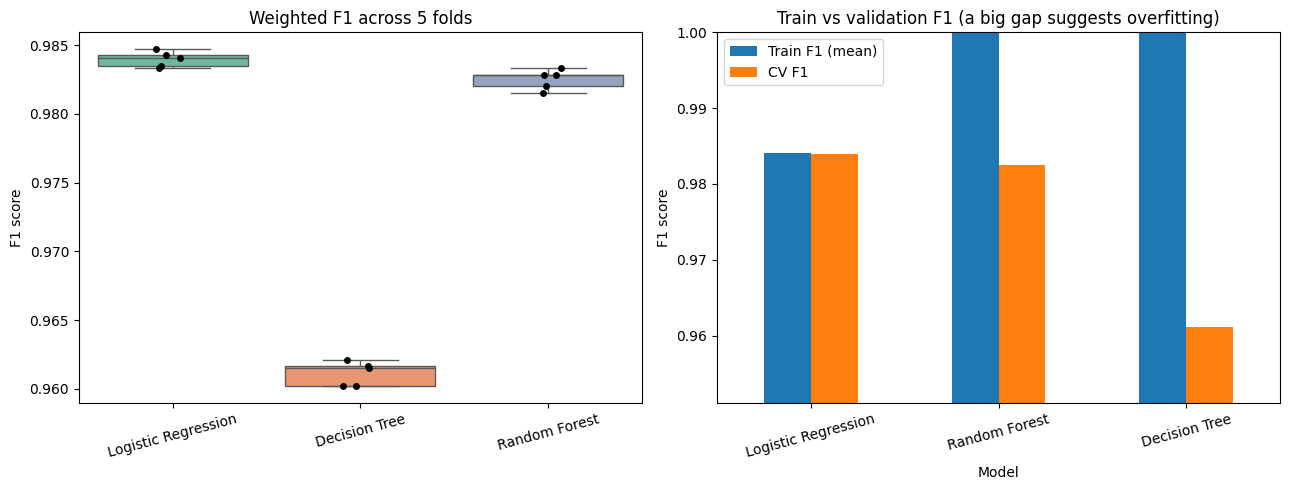

In [13]:
# Per-fold F1 for every model: shows stability across folds
fold_df = pd.DataFrame({
    name: s["test_f1"] for name, s in cv_fold_scores.items()
})
fold_df.index = [f"Fold {i}" for i in range(1, N_SPLITS + 1)]
display(fold_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=fold_df, ax=axes[0], palette="Set2")
sns.stripplot(data=fold_df, ax=axes[0], color="black", size=5)
axes[0].set_title(f"Weighted F1 across {N_SPLITS} folds")
axes[0].set_ylabel("F1 score")
axes[0].tick_params(axis="x", rotation=15)

gap = cv_results_df.set_index("Model")[["Train F1 (mean)", "CV F1"]]
gap.plot(kind="bar", ax=axes[1], rot=15, ylim=(gap.min().min() - 0.01, 1.0))
axes[1].set_title("Train vs validation F1 (a big gap suggests overfitting)")
axes[1].set_ylabel("F1 score")

plt.tight_layout()
plt.show()

In [14]:
# Choose the model on CV score (not on the test set)
best_cv_name = cv_results_df.loc[0, "Model"]
print("Best model by CV weighted F1:", best_cv_name)
print(f"  CV F1 = {cv_results_df.loc[0, 'CV F1']:.4f} +/- {cv_results_df.loc[0, 'F1 Std']:.4f}")

# If the top models are within one standard deviation of each other,
# prefer the simpler / smaller one for deployment
top_two = cv_results_df.head(2)
if (top_two["CV F1"].iloc[0] - top_two["CV F1"].iloc[1]) < top_two["F1 Std"].iloc[0]:
    print("\nNote: the top two models are statistically very close.",
          "Consider the simpler one (smaller file, faster predictions) for deployment.")

Best model by CV weighted F1: Logistic Regression
  CV F1 = 0.9840 +/- 0.0005


Final model: Logistic Regression
Test accuracy: 0.9839
CV accuracy:   0.9840  (should be close to the test score)

Classification report:
              precision    recall  f1-score   support

        Fail       0.96      0.95      0.95      3452
        Pass       0.99      0.99      0.99     16548

    accuracy                           0.98     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.98      0.98      0.98     20000



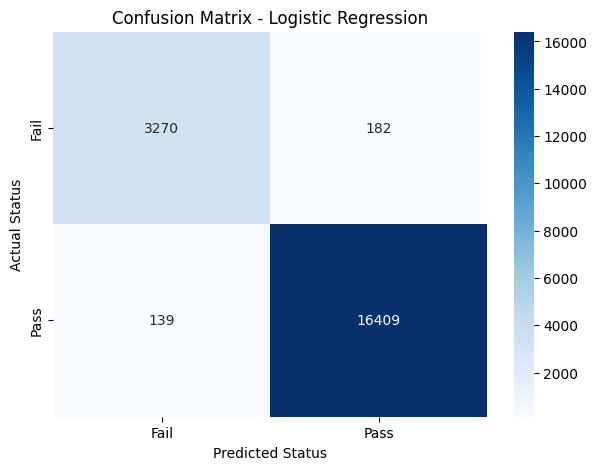

In [15]:
# Final model: full Pipeline (preprocessor + model) refitted on the entire training set,
# then evaluated ONCE on the untouched test set.
from sklearn.base import clone

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", clone(models[best_cv_name])),
])
final_pipeline.fit(X_train, y_train)
test_predictions = final_pipeline.predict(X_test)

print("Final model:", best_cv_name)
print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(f"CV accuracy:   {cv_results_df.loc[0, 'CV Accuracy']:.4f}  (should be close to the test score)")
print("\nClassification report:")
print(classification_report(y_test, test_predictions, zero_division=0))

plt.figure(figsize=(7, 5))
sns.heatmap(
    confusion_matrix(y_test, test_predictions),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=final_pipeline.classes_, yticklabels=final_pipeline.classes_,
)
plt.title(f"Confusion Matrix - {best_cv_name}")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.show()

## Save for deployment

We save the **complete pipeline** (preprocessing + model) in one file, so the web app can take raw inputs and does not need to repeat any preprocessing code. The `scikit-learn` version is saved with it, because pickled models must be loaded with the same version.

In [16]:
import joblib, sklearn, json

ARTIFACT = {
    "pipeline": final_pipeline,
    "features": X.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "classes": final_pipeline.classes_.tolist(),
    "model_name": best_cv_name,
    "sklearn_version": sklearn.__version__,
    "cv_f1_mean": float(cv_results_df.loc[0, "CV F1"]),
    "cv_f1_std": float(cv_results_df.loc[0, "F1 Std"]),
    "test_accuracy": float(accuracy_score(y_test, test_predictions)),
}

joblib.dump(ARTIFACT, "student_status_pipeline.joblib", compress=3)

results_df.to_csv("model_comparison_results.csv", index=False)
cv_results_df.to_csv("cross_validation_results.csv", index=False)

size_mb = os.path.getsize("student_status_pipeline.joblib") / 1e6
print(f"Saved student_status_pipeline.joblib ({size_mb:.1f} MB)")
print("scikit-learn version used for training:", sklearn.__version__)
print("Put this in requirements.txt ->", f"scikit-learn=={sklearn.__version__}")

Saved student_status_pipeline.joblib (0.0 MB)
scikit-learn version used for training: 1.6.1
Put this in requirements.txt -> scikit-learn==1.6.1
